## Region Adjacency Graph (RAG) or the Pore Graph
In this tutorial, we explain, compute and analyze the region adjacency graph of our region segmentation. RAG is not a new concept, in fact, it has been recently implemented in scikit-image [RAG skimage](https://scikit-image.org/docs/stable/api/skimage.future.graph.html?highlight=rag#skimage.future.graph.RAG). However, we build it with some modifications.

RAG is simply a graph of the touching regions in an image. In our case, the nodes of the graph represent the pockets the position of the node can be set at the local maxima (or the centroid) of the region. The edges represent an actual connection in the cavities, where one pore is connected to another through a pore window. Hence, in this context the terms RAG and pore graph are used interchangeably. Pore graph is very useful, because:

- It can be annotated with any property of the pores, size, shape, etc.
- It gives an overview of the overall pore structure of the material.
- It allows you recognize patterns within a pore structure.
- It allows you to retain relevant information about the pore structure, without having to work with large 3D grids.
- You can compare pore structures of different materials by comparing their pore graphs.

In this tutorial, we will be relying on all the tutorials up to the 'Applying PBC' tutorial. Although, not all of them are required to construct the pore graph, all the additional information we will add to the pore graph will be based on the previous tutorials. Hence, it is recommended to go through all the tutorials before this one. Let's get up to speed, as before, we will not be explaning the build-up steps in detail.

## Imports

In [1]:
import sys
import os
# * Put your path here
path_to_mgr = os.path.abspath(
    'c:/Users/Arun Gopalan/OneDrive - The University of Manchester/my_cloned_repos/mofography')
sys.path.append(path_to_mgr)

import mofography as mgr

path_to_cif = os.path.join(path_to_mgr, 'examples',
                           'TestCIFs', 'P1-IRMOF-1.cif')


## Read the structure

In [2]:
from ase.io import read
mat_atoms = read(path_to_cif)
mat_updated = mgr.update_with_covalent_bonds(mat_atoms)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\io\cif.py:401: UserWarning: crystal system 'triclinic' is not interpreted for space group Spacegroup(1, setting=1). This may result in wrong setting!
  warnings.warn(


## Compute the distance grid

In [3]:
dgrid = mgr.dgrid_from_atoms(mat_atoms, spacing=0.25)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning: Please use atoms.cell.cellpar() instead
  warnings.warn(warning)
Computing distance grid: 100%|██████████| 23/23 [00:03<00:00,  6.00it/s]


## Compute the region segmentation

In [4]:
regions, maxima = mgr.regions_from_dgrid(dgrid.compute()) 

c:\users\arun gopalan\onedrive - the university of manchester\my_cloned_repos\mofography_general\mofography\mofography\compute.py:446: UserWarning: Some maxima excluded as they fell inside the mask_thickness
  warnings.warn('Some maxima excluded as they fell inside the mask_thickness')


## Apply periodic boundary conditions

In [5]:
maxima_radii = dgrid.compute()[tuple(maxima.T)]
regions_pbc = mgr.apply_pbc(regions, maxima, maxima_radii, mat_atoms )
pbc_groups= mgr.apply_pbc(regions, maxima, maxima_radii, mat_atoms , return_conn=True)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\utils\__init__.py:62: FutureWarning: Please use atoms.cell.cellpar() instead
  warnings.warn(warning)


## Constructing the Region Adjacency Graph (RAG) or the Pore Graph

There are a few ways in mofography to generate the pore graph from what we have so far. Perhaps the easiest option is to use the `get_rag_from_regions_and_grid` function. It also needs the ASE atoms object, the `maxima` maybe provided as an argument if you'd like to fix the locations of the node manually or to speed up the calculations a little bit. If not provided, the local maxima of the distance grid will be computed on the fly as in the region segmentation step.

However, this is not the recommended option, because it tends to fail when there is only one region in the box, which is quite common in nanoporous materials due to PBC. Hence, the slower robust option is to compute the connections first and then compute the RAG from the connections list. 'connections' is a list that contains information about the connections between regions in the material and the corresponding pore windows. Please refer to the window detection tutorial for detailed explanation and examples.


Let's try make the RAG both ways, for IRMOF-1, CuBTC etc, both approaches give same results.

*Note: that you shouldn't use the `regions_pbc` instead of `regions` here, because the number of unique regions will not match the number of maxima in the box, and will result in an error. We will the PBC information as an additional property to the pore graph in the next step.*

#### Option 1: Using the `get_rag_from_regions_and_grid` function (NOT RECOMMENDED)


In [6]:
rag = mgr.get_rag_from_regions_and_grid(regions, dgrid.compute(), mat_atoms, maxima)

#### Option 2: Compute connections first and then compute the RAG from the connections list (RECOMMENDED)
Please refer to the window detection tutorial for detailed explanation and examples on the connections list.

In [7]:

connections = mgr.connections_from_regions_and_dgrid(regions, dgrid.compute(), maxima, mat_atoms)

rag = mgr.rag_from_connections(connections, maxima)
#* let's add some properties to the RAG
shape = dgrid.shape
#* add the maxima to the rag
rag = mgr.add_maxima_to_rag(rag, maxima, maxima_radii, shape, mat_atoms)
#* add the region props from skiamge
# props = mgr.get_region_props_for_regions(regions)
# rag = mgr.add_props_to_rag(rag, props)


This is a networkx style graph object, hence all the networkx functions to obtain attributes or to manipulate the graph are available. For example, to get the nodes and edges of the graph use:

In [8]:
import networkx as nx 

rag.nodes(), rag.edges()

(NodeView((1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27)),
 EdgeView([(1, 2), (1, 4), (1, 10), (2, 3), (2, 6), (2, 16), (3, 5), (3, 11), (4, 6), (4, 7), (4, 17), (5, 6), (5, 9), (5, 12), (6, 8), (6, 18), (7, 8), (7, 13), (8, 9), (8, 14), (9, 15), (10, 16), (10, 17), (10, 19), (11, 12), (11, 16), (11, 21), (12, 15), (12, 18), (12, 24), (13, 14), (13, 17), (13, 25), (14, 15), (14, 18), (14, 26), (15, 27), (16, 18), (16, 20), (17, 18), (17, 22), (18, 23), (19, 20), (19, 22), (20, 21), (20, 23), (21, 24), (22, 23), (22, 25), (23, 24), (23, 26), (24, 27), (25, 26), (26, 27)]))

## Grabbing graph attributes
You can get the node/edge data by turning on the `data=True` flag. For example, to get the node data for node 1 (note that key 0 is reserved for the background):

In [9]:
rag.nodes(data=True)[1]

{'labels': [1],
 'maxima': array([0.24838462, 0.24838462, 0.24838462]),
 'maxima_indices': array([1, 1, 1], dtype=int64),
 'maxima_radii': 7.151892471313476}

as you can see, there are already a few properties added on to the nodes. If you'd like to grab the information key `centroid` for all the nodes, you can use:

In [10]:
nx.get_node_attributes(rag, 'maxima')

{1: array([0.24838462, 0.24838462, 0.24838462]),
 2: array([ 0.24838462,  0.24838462, 12.66761538]),
 3: array([ 0.24838462,  0.24838462, 25.33523077]),
 4: array([ 0.24838462, 12.66761538,  0.24838462]),
 5: array([ 0.24838462, 12.66761538, 25.33523077]),
 6: array([ 0.24838462, 12.916     , 12.916     ]),
 7: array([ 0.24838462, 25.33523077,  0.24838462]),
 8: array([ 0.24838462, 25.33523077, 12.66761538]),
 9: array([ 0.24838462, 25.33523077, 25.33523077]),
 10: array([12.66761538,  0.24838462,  0.24838462]),
 11: array([12.66761538,  0.24838462, 25.33523077]),
 12: array([12.66761538, 12.66761538, 25.33523077]),
 13: array([12.66761538, 25.33523077,  0.24838462]),
 14: array([12.66761538, 25.33523077, 12.66761538]),
 15: array([12.66761538, 25.33523077, 25.33523077]),
 16: array([12.916     ,  0.24838462, 12.916     ]),
 17: array([12.916     , 12.916     ,  0.24838462]),
 18: array([12.916, 12.916, 12.916]),
 19: array([25.33523077,  0.24838462,  0.24838462]),
 20: array([25.33523

similarly, you can use `nx.set_node_attributes` to set the attributes for all the nodes. Please refer to the networkx documentation for more information, which is available [here](https://networkx.org/documentation/stable/reference/classes/generated/networkx.Graph.nodes.html). Similar manipulations are available for the edges as well.

## Adding properties

For example, let's add the information about periodic boundary conditions to the pore graph. This will add the pbc group to which the node belongs to to the rag under the key `pbc_group`

In [11]:
rag = mgr.add_pbc_to_rag(rag,pbc_groups)

rag.nodes[1]

{'labels': [1],
 'maxima': array([0.24838462, 0.24838462, 0.24838462]),
 'maxima_indices': array([1, 1, 1], dtype=int64),
 'maxima_radii': 7.151892471313476,
 'pbc_group': 0}

We can also add the pocket detection information into the RAG. But we will explore that in the `Pockets Detection` tutorial.

## Visualizing the pore graph

mofography has a built-in function to make a plot trace of the RAG that plays well with the rest of the visualization capabilities. Let's first make traces for all the usual things, like the framework, the distance surface colored by regions etc. If anything here is unclear, please refer to the previous tutorials.

In [12]:
import plotly.express as px 

cscale = px.colors.qualitative.Pastel_r

frame_trace= mgr.plot_framework_as_mesh(mat_updated, stylize=True)
cell_trace = mgr.plot_cell(mat_updated)
isosurface_trace =  mgr.plot_surface_dgrid(dgrid.compute(), isovalue=1.75, ase_atoms  = mat_updated, opacity=0.7, region_labels=regions, cscale=cscale, stylize=True)
maxima_trace = mgr.plot_maxima(dgrid.compute(), maxima, ase_atoms = mat_updated)

c:\Users\Public\anaconda3\envs\test\lib\site-packages\ase\atoms.py:967: VisibleDeprecationWarning: Use get_global_number_of_atoms() instead
  warnings.warn('Use get_global_number_of_atoms() instead',


No node props provided, using default set: [position, scaled_position, element and atomic_number]
No edge properties provided. Use the default set: [bond_order, bond_type]
isomorphic aromatic cycles is None, trying to calculate


c:\users\arun gopalan\onedrive - the university of manchester\my_cloned_repos\mofography_general\mofography\mofography\visualize.py:814: UserWarning: Optimal rotation is not uniquely or poorly defined for the given sets of vectors.
  r = R.align_vectors(ring_normal.reshape(-1, 3), np.array([0, 0, 1]).reshape(-1, 3))


Now let's make a trace for the RAG and add that to the figure

In [13]:
rag_trace = mgr.plot_rag(rag, name='Pore Graph')

In [14]:
import plotly.graph_objects as go
fig=go.Figure(data=[*frame_trace, cell_trace, isosurface_trace, maxima_trace, rag_trace]).update(layout=mgr.white_layout)

Use `renderer='notebook_connected'` to make the plot interactive and show it in the notebook. You can also use `renderer='browser'` to make the plot interactive and open it in your browser. For the time being, it's just a static png image to save space.

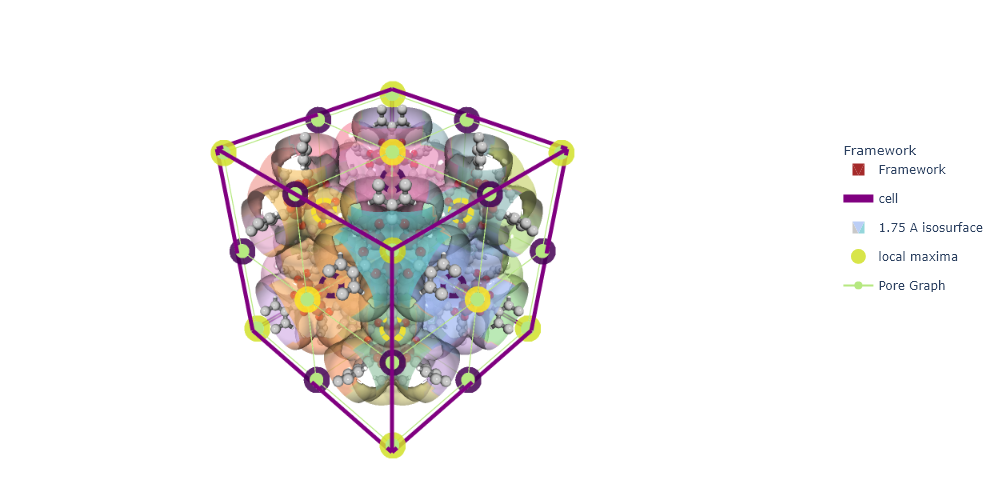

In [15]:
fig.show(renderer='png', width=1000)

## Where to go next?

In the next tutorial, we will be looking at detecting the types of pockets in a material and how to add that information to the pore graph.